# Multimodal RAG Lab — Scenario 1: Text-Only Proxy (OCR + VLM Captioning)

**Architecture 1 Pipeline:**
- **Ingestion:** `Image` $\rightarrow$ `Pre-process (OpenCV)` $\rightarrow$ `Extract Text (OCR) + Describe Visuals (VLM)` $\rightarrow$ `Summarize (Qwen2.5-1.5B)` $\rightarrow$ `Embed Summary Text (all-MiniLM-L6-v2)` $\rightarrow$ `Store Vector + Image Path in Qdrant`
- **Retrieval:** `User Text Query` $\rightarrow$ `Text Embedding (all-MiniLM-L6-v2)` $\rightarrow$ `Cosine Similarity Search against Summary Vectors` $\rightarrow$ `Fetch & Display Linked Original Image`

## Step 1: Load Image & Pre-process with OpenCV (`cv2`)
We load `Document/IVI_Data.jpg`, convert it to grayscale, enhance local contrast using **CLAHE** (Contrast Limited Adaptive Histogram Equalization), and apply mild denoising so the OCR engine can read every button label accurately.

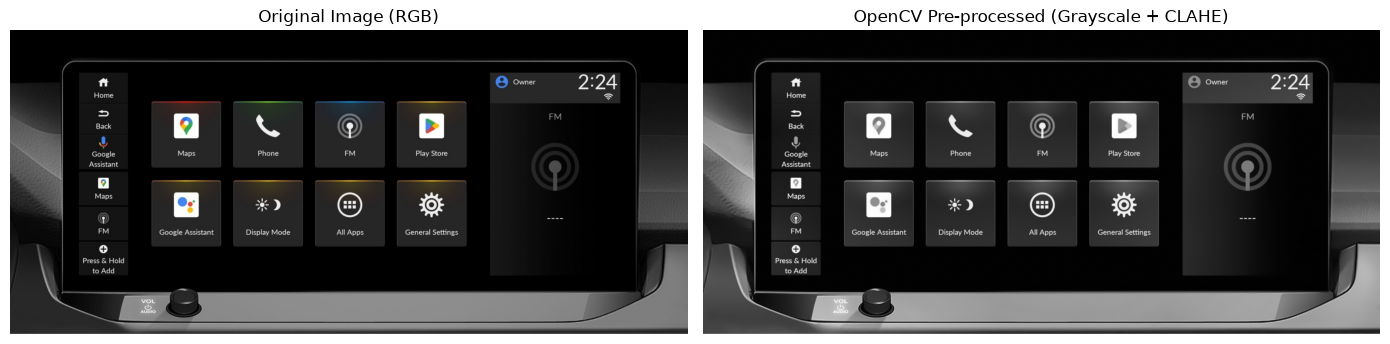

In [1]:
# Import Path for OS-safe file path handling and gc for memory management on 8GB RAM
import gc
from pathlib import Path

# Import OpenCV for image pre-processing and Matplotlib for visualization
import cv2
import matplotlib.pyplot as plt

# Define the absolute path to your Honda IVI dataset image
IMAGE_PATH = Path(r"D:\multimodel-rag-lab\Document\IVI_Data.jpg")

# Ensure the file exists before running the pipeline
assert IMAGE_PATH.exists(), f"File not found: {IMAGE_PATH}"

# Read the image from disk using OpenCV (loads in BGR color order by default)
img_bgr = cv2.imread(str(IMAGE_PATH))

# Convert BGR to RGB so we can display the true colors in Matplotlib
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Convert BGR to Grayscale (1 channel) because OCR works best on high-contrast intensity values
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Create a CLAHE object to boost local contrast across the dark infotainment screen
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

# Apply CLAHE contrast enhancement to the grayscale image
img_clahe = clahe.apply(img_gray)

# Apply mild non-local means denoising to remove JPEG compression artifacts around small letters
img_preprocessed = cv2.fastNlMeansDenoising(img_clahe, None, h=10, templateWindowSize=7, searchWindowSize=21)

# Visualize Original vs. OpenCV Pre-processed image side-by-side
fig, ax = plt.subplots(1, 2, figsize=(14, 5))                # Create 1 row with 2 subplots
ax[0].imshow(img_rgb)                                        # Left plot: Original RGB image
ax[0].set_title("Original Image (RGB)")                      # Set title for left plot
ax[0].axis("off")                                            # Hide axis rulers

ax[1].imshow(img_preprocessed, cmap="gray")                  # Right plot: OpenCV Pre-processed image
ax[1].set_title("OpenCV Pre-processed (Grayscale + CLAHE)")  # Set title for right plot
ax[1].axis("off")                                            # Hide axis rulers
plt.tight_layout()                                           # Prevent title overlap
plt.show()                                                   # Render in notebook
plt.close(fig)                                               # Free figure memory

## Step 2A: Extract Text with OCR (`RapidOCR`)
We run `RapidOCR` on the OpenCV pre-processed image to extract all visible text strings (`Home`, `Back`, `Google Assistant`, `Maps`, `Phone`, `FM`, `Play Store`, `Display Mode`, `All Apps`, `General Settings`, `Owner`, `2:24`, `VOL AUDIO`) along with their `(x, y)` coordinates, and then free the OCR engine from RAM.

In [2]:
# Import RapidOCR for CPU text extraction
from rapidocr_onnxruntime import RapidOCR

# Initialize the RapidOCR engine (runs on CPU via ONNX Runtime)
ocr = RapidOCR()

# Run OCR on our OpenCV pre-processed image (returns list of [bounding_box, text, confidence])
ocr_results, _ = ocr(img_preprocessed)

# Extract each text string and its (x, y) pixel position on the screen
ocr_items = []                                               # List to hold formatted OCR strings
for bbox, text, confidence in ocr_results:                   # Iterate over every detected text region
    x, y = int(bbox[0][0]), int(bbox[0][1])                  # Top-left X and Y coordinate of the text box
    ocr_items.append(f"'{text}' (pos: x={x}, y={y}, conf={confidence:.2f})")

# Join all detected text items into a single string
extracted_ocr_text = "\n".join(ocr_items)

# Free the ONNX Runtime OCR session from RAM before loading the VLM
del ocr, ocr_results
gc.collect()

# Print the OCR output
print("=== 1. Extracted Text (OCR) ===")
print(extracted_ocr_text)

=== 1. Extracted Text (OCR) ===
'2:24' (pos: x=1807, y=133, conf=1.00)
'Owner' (pos: x=1601, y=151, conf=0.99)
'Home' (pos: x=264, y=192, conf=1.00)
'FM' (pos: x=1712, y=257, conf=1.00)
'Back' (pos: x=272, y=292, conf=1.00)
'Google' (pos: x=258, y=379, conf=1.00)
'Maps' (pos: x=531, y=374, conf=1.00)
'Phone' (pos: x=786, y=374, conf=0.99)
'FM' (pos: x=1063, y=377, conf=1.00)
' Play Store' (pos: x=1287, y=374, conf=0.96)
'Assistant' (pos: x=250, y=414, conf=1.00)
'Maps' (pos: x=267, y=511, conf=1.00)
'FM' (pos: x=277, y=625, conf=1.00)
'Google Assistant' (pos: x=473, y=629, conf=0.97)
'Display Mode' (pos: x=750, y=629, conf=0.97)
'AllApps' (pos: x=1037, y=627, conf=0.96)
'General Settings' (pos: x=1256, y=627, conf=0.97)
'Press&Hold' (pos: x=229, y=720, conf=0.99)
'toAdd' (pos: x=258, y=751, conf=1.00)
'VOL' (pos: x=415, y=853, conf=0.99)


## Step 2B: Describe Visuals with VLM (`Qwen2-VL-2B-Instruct-GGUF`)
We use `Qwen2-VL-2B-Instruct-Q4_K_M.gguf` + `mmproj-Qwen2-VL-2B-Instruct-f16.gguf` with **8 GB RAM safe settings** (`n_ctx=512`, `n_batch=64`, `warmup=False`, `image_max_tokens=256`, and a `448x196` resized image) to describe the visual layout, icons, colors, and physical controls.

In [3]:
# Import ctypes for C++ MTMD bindings
import ctypes
import llama_cpp
import llama_cpp.mtmd_cpp as mtmd_cpp
from llama_cpp import Llama

# Resize image to 448x196 (112 vision tokens instead of 2670) so VLM runs in ~8 seconds on CPU
img_vlm_small = cv2.resize(img_bgr, (448, 196), interpolation=cv2.INTER_AREA)
_, img_buf = cv2.imencode(".jpg", img_vlm_small)             # Encode resized image to JPEG buffer in memory
img_bytes = bytes(img_buf)                                   # Convert buffer to raw bytes for mtmd

# Paths to your local Qwen2-VL-2B GGUF weights and f16 multimodal vision projector
VLM_MODEL_PATH = r"D:\Bmw_Usecase\Models\Qwen2-VL-2B-Instruct-GGUF\Qwen2-VL-2B-Instruct-Q4_K_M.gguf"
MMPROJ_PATH = r"D:\Bmw_Usecase\Models\Qwen2-VL-2B-Instruct-GGUF\mmproj-Qwen2-VL-2B-Instruct-f16.gguf"

# Load the Qwen2-VL-2B backbone model on CPU with compact context & 128 batch size (>112 image tokens)
vlm = Llama(
    model_path=VLM_MODEL_PATH,                               # Path to Q4_K_M GGUF weights
    n_ctx=512,                                               # Compact 512 context window
    n_batch=128,                                             # 128 fits all 112 image tokens in 1 batch
    n_ubatch=128,                                            # Micro-batch size matching n_batch
    n_threads=4,                                             # Use 4 physical CPU cores
    verbose=False                                            # Suppress C++ logs
)

# Configure low-RAM MTMD vision parameters (disables the 4.8GB dummy warmup allocation!)
ctx_params = mtmd_cpp.mtmd_context_params_default()          # Get default MTMD C++ struct
ctx_params.use_gpu = False                                   # Run purely on CPU
ctx_params.print_timings = False                             # Quiet mode
ctx_params.n_threads = 4                                     # Use 4 CPU threads for vision encoding
ctx_params.warmup = False                                    # CRITICAL: Prevent 1288x1288 (4.8GB) dummy warmup
ctx_params.image_min_tokens = 64                             # Minimum vision tokens
ctx_params.image_max_tokens = 256                            # Cap vision tokens so compute buffer is only ~14 MB

# Initialize the MTMD vision context linked to the loaded vlm model
mtmd_ctx = mtmd_cpp.mtmd_init_from_file(MMPROJ_PATH.encode("utf-8"), vlm.model, ctx_params)

# Build the Qwen2-VL chat prompt with the default media marker (<__media__>)
media_marker = mtmd_cpp.mtmd_default_marker().decode("utf-8")
vlm_prompt = (
    "<|im_start|>system\nYou are a helpful automotive UI assistant.<|im_end|>\n"
    f"<|im_start|>user\n<|vision_start|>{media_marker}<|vision_end|>"
    "Describe the visual layout, app icons, colors, left sidebar, right panel, and physical controls in this car screen.<|im_end|>\n"
    "<|im_start|>assistant\n"
)

# Create an MTMD bitmap structure from our resized JPEG bytes
c_buf = (ctypes.c_uint8 * len(img_bytes)).from_buffer(bytearray(img_bytes))
bitmap = mtmd_cpp.mtmd_helper_bitmap_init_from_buf(mtmd_ctx, c_buf, len(img_bytes), False)
bitmap_array = (mtmd_cpp.mtmd_bitmap_p_ctypes * 1)(bitmap)

# Tokenize the combined text + image prompt into MTMD chunks
input_text = mtmd_cpp.mtmd_input_text(vlm_prompt.encode("utf-8"), len(vlm_prompt.encode("utf-8")), True, True)
chunks = mtmd_cpp.mtmd_input_chunks_init()
mtmd_cpp.mtmd_tokenize(mtmd_ctx, chunks, ctypes.byref(input_text), bitmap_array, 1)

# Evaluate all prompt & image chunks natively in C++ using 4D M-RoPE positions
new_n_past = llama_cpp.llama_pos(0)
mtmd_cpp.mtmd_helper_eval_chunks(
    mtmd_ctx, vlm._ctx.ctx, chunks, llama_cpp.llama_pos(0), llama_cpp.llama_seq_id(0), 128, True, ctypes.byref(new_n_past)
)
n_past = new_n_past.value                                    # Track current M-RoPE position index

# Generate up to 140 tokens using in-place 4D M-RoPE coordinates [t, x, y, 0] in vlm._batch.batch.pos
generated_tokens = []
for _ in range(140):
    vlm.n_tokens = max(1, len(generated_tokens))             # Ensure sampler knows tokens are present
    token_id = vlm.sample(temp=0.2)                          # Sample next token with low temperature
    if llama_cpp.llama_vocab_is_eog(vlm._model.vocab, token_id):
        break                                                # Stop if End-Of-Generation token is reached
    generated_tokens.append(token_id)                        # Append token ID to output list
    vlm._batch.batch.n_tokens = 1                            # Prepare batch of size 1 for next decode step
    vlm._batch.batch.token[0] = token_id                     # Set token ID
    vlm._batch.batch.pos[0] = n_past                         # M-RoPE dim 0 (t)
    vlm._batch.batch.pos[1] = n_past                         # M-RoPE dim 1 (x)
    vlm._batch.batch.pos[2] = n_past                         # M-RoPE dim 2 (y)
    vlm._batch.batch.pos[3] = 0                              # M-RoPE dim 3 (unused = 0)
    vlm._batch.batch.seq_id[0][0] = 0                        # Sequence ID 0
    vlm._batch.batch.n_seq_id[0] = 1                         # 1 sequence
    vlm._batch.batch.logits[0] = True                        # Compute logits for this token
    vlm._ctx.decode(vlm._batch)                              # Run forward pass for single token
    n_past += 1                                              # Advance position counter

# Decode generated tokens into a UTF-8 string
visual_description = vlm.detokenize(generated_tokens).decode("utf-8", errors="ignore").strip()

# Clean up C++ chunks, bitmap, MTMD vision context, and VLM backbone immediately
mtmd_cpp.mtmd_input_chunks_free(chunks)
mtmd_cpp.mtmd_bitmap_free(bitmap)
mtmd_cpp.mtmd_free(mtmd_ctx)
vlm.close()
del vlm
gc.collect()

# Print the visual description generated by the VLM
print("=== 2. Visual Description (VLM) ===")
print(visual_description)

=== 2. Visual Description (VLM) ===
The car screen in the image displays a modern, user-friendly interface with a combination of digital and physical controls. Here is a detailed description of the visual layout, app icons, colors, left sidebar, right panel, and physical controls:

### Visual Layout:
- **Main Interface**: The main interface is divided into several sections with a central navigation bar and a large display area.
- **Navigation Bar**: At the top, there is a navigation bar with several icons:
  - **Back**: This icon is typically used to return to the previous screen or menu.
  - **Maps**: This icon likely leads to the vehicle's navigation system.
  - **Phone**: This icon may lead to the vehicle


## Step 3: Summarize (`OCR Text` + `VLM Visual Description` $\rightarrow$ `Qwen2.5-1.5B-Instruct-GGUF`)
Now we pass both the **exact OCR text** and the **VLM visual layout description** into your existing `Qwen2.5-1.5B-Instruct-GGUF` model to synthesize a unified, keyword-rich **Image Summary**.

In [4]:
# Path to your already-downloaded Qwen2.5-1.5B-Instruct GGUF model
SUMMARIZER_GGUF_PATH = r"D:\Bmw_Usecase\Models\Qwen2.5-1.5B-Instruct-GGUF\qwen2.5-1.5b-instruct-q4_k_m.gguf"

# Load the text-only Qwen2.5-1.5B-Instruct model on CPU with low-RAM settings
summarizer_llm = Llama(
    model_path=SUMMARIZER_GGUF_PATH,                         # Path to your existing 1.5B GGUF file
    n_ctx=1024,                                              # 1024 token context window
    n_batch=64,                                              # Compact batch size
    n_threads=4,                                             # 4 CPU threads
    verbose=False                                            # Quiet mode
)

# Build the prompt combining both OCR text and VLM visual description
summary_messages = [
    {
        "role": "system",
        "content": (
            "You are an expert technical indexer for an automotive Multimodal RAG system. "
            "Combine the provided OCR text and visual description into a single, comprehensive, "
            "keyword-rich paragraph summarizing the infotainment screen. Explicitly list every "
            "detected text label, app name, sidebar shortcut, status indicator, and physical control."
        )
    },
    {
        "role": "user",
        "content": (
            f"OCR Extracted Text:\n{extracted_ocr_text}\n\n"
            f"Visual Description:\n{visual_description}\n\n"
            "Write the unified searchable summary:"
        )
    }
]

# Run chat completion on CPU to produce the unified summary
summary_output = summarizer_llm.create_chat_completion(
    messages=summary_messages,                               # Input prompt messages
    max_tokens=220,                                          # Max length of the summary
    temperature=0.1                                          # Very low temperature to prevent hallucination
)

# Extract the final summary text string
final_image_summary = summary_output["choices"][0]["message"]["content"].strip()

# Free the summarizer LLM from RAM immediately
summarizer_llm.close()
del summarizer_llm
gc.collect()

# Display the final summary that will represent our image in the Vector DB
print("=== 3. Final Unified Image Summary (To Be Embedded) ===")
print(final_image_summary)

=== 3. Final Unified Image Summary (To Be Embedded) ===
The infotainment screen displays a modern, user-friendly interface with a combination of digital and physical controls. The main interface is divided into several sections with a central navigation bar and a large display area. The navigation bar includes icons for "Back," "Maps," and "Phone." The "Back" icon is used to return to the previous screen or menu, the "Maps" icon leads to the vehicle's navigation system, and the "Phone" icon may lead to the vehicle. The "FM" icon is used to change the radio station. The "Play Store" icon leads to the app store, and the "Assistant" icon is used for voice commands. The "Display Mode" icon allows switching between different display modes. The "AllApps" icon opens the app menu, and the "General Settings" icon allows adjusting general settings. The "Press&Hold" icon is used to add items to the list. The "VOL" icon controls the volume.


## Step 4 & 5: Embed Summary Text (`all-MiniLM-L6-v2`) & Store in Vector DB (`Qdrant`)
We embed `final_image_summary` into a `384`-dimensional normalized vector using your local `all-MiniLM-L6-v2` model and store it in local Qdrant (`./local_qdrant`) linked to `IMAGE_PATH`.

In [5]:
# Import SentenceTransformer to load your local text embedding model
from sentence_transformers import SentenceTransformer

# Import QdrantClient and data models for creating collections and storing vectors
from qdrant_client import QdrantClient
from qdrant_client.models import Distance, VectorParams, PointStruct

# Path to your existing local all-MiniLM-L6-v2 model in D:\Bmw_Usecase
TEXT_EMBED_MODEL_PATH = r"D:\Bmw_Usecase\Embedding Model\all-MiniLM-L6-v2"

# Load the text embedding model on CPU
text_embedder = SentenceTransformer(TEXT_EMBED_MODEL_PATH, device="cpu")

# Encode the unified image summary into a normalized 384-dimensional float vector
summary_embedding = text_embedder.encode(
    final_image_summary,                                     # The text summary representing our image
    normalize_embeddings=True                                # Normalize to unit length for cosine similarity
).tolist()                                                   # Convert numpy array to standard Python list

# Verify the vector size (should be 384 for all-MiniLM-L6-v2)
print(f"Generated Summary Embedding Dimension: {len(summary_embedding)}")
print(f"First 5 vector values: {summary_embedding[:5]}")

# Initialize a local, persistent Qdrant database inside your project directory
qdrant_client = QdrantClient(path=r"D:\multimodel-rag-lab\local_qdrant")

# Name the collection for Scenario 1 (Text-Only Proxy)
COLLECTION_SCENARIO_1 = "scenario1_text_proxy"

# If the collection already exists from a previous run, delete it to start fresh
if qdrant_client.collection_exists(COLLECTION_SCENARIO_1):
    qdrant_client.delete_collection(COLLECTION_SCENARIO_1)

# Create the Qdrant collection with 384 dimensions and Cosine distance metric
qdrant_client.create_collection(
    collection_name=COLLECTION_SCENARIO_1,                   # Name of the collection
    vectors_config=VectorParams(
        size=len(summary_embedding),                         # 384 dimensions
        distance=Distance.COSINE                             # Cosine similarity metric
    )
)

# Store (Upsert) the summary vector + metadata (including the original image file path)
qdrant_client.upsert(
    collection_name=COLLECTION_SCENARIO_1,                   # Target collection
    points=[
        PointStruct(
            id=1,                                            # Unique ID for this image entry
            vector=summary_embedding,                        # The 384-d summary text vector
            payload={                                        # Metadata linked to this vector
                "image_path": str(IMAGE_PATH),               # File path to fetch the original image on retrieval
                "scenario": "Scenario 1: Text-Only Proxy",   # Architecture label
                "ocr_text": extracted_ocr_text,              # Raw OCR text
                "visual_description": visual_description,    # Raw VLM description
                "summary": final_image_summary               # Final embedded summary text
            }
        )
    ]
)

print(f"Successfully stored vector + image path in Qdrant collection: '{COLLECTION_SCENARIO_1}'")

Generated Summary Embedding Dimension: 384
First 5 vector values: [-0.025227444246411324, 0.03249127417802811, -0.03581767529249191, -0.0680234432220459, -0.04414514824748039]
Successfully stored vector + image path in Qdrant collection: 'scenario1_text_proxy'


## Step 6: Retrieval Pipeline & Testing with Sample Queries
We test **Scenario 1** with 3 different queries:
1. **Query 1 (App / UI Navigation Query):** Tests retrieval using exact app names (`Google Assistant`, `Maps`, `General Settings`).
2. **Query 2 (Status Bar & Hardware Control Query):** Tests retrieval using clock time (`2:24`), profile (`Owner`), and rotary volume knob (`VOL AUDIO`).
3. **Query 3 (Subtle Visual Detail Query — Testing Scenario 1's Limitation):** Searches for fine visual details (`rainbow glowing top borders in red, green, blue, and yellow on black app tiles`) that a text proxy summary typically misses!

USER QUERY       : How do I open Google Assistant, Maps, and General Settings on the car screen?
SIMILARITY SCORE : 0.5300
LINKED IMAGE PATH: D:\multimodel-rag-lab\Document\IVI_Data.jpg
--------------------------------------------------------------------------------


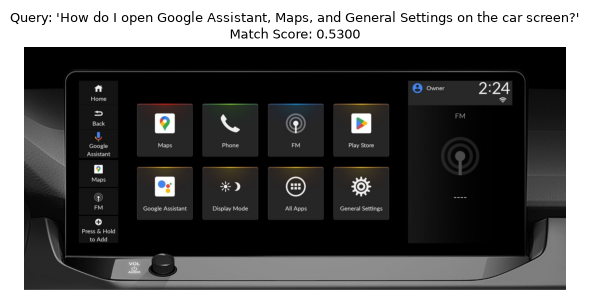

USER QUERY       : Infotainment screen showing Owner profile, clock at 2:24, and VOL AUDIO knob
SIMILARITY SCORE : 0.4295
LINKED IMAGE PATH: D:\multimodel-rag-lab\Document\IVI_Data.jpg
--------------------------------------------------------------------------------


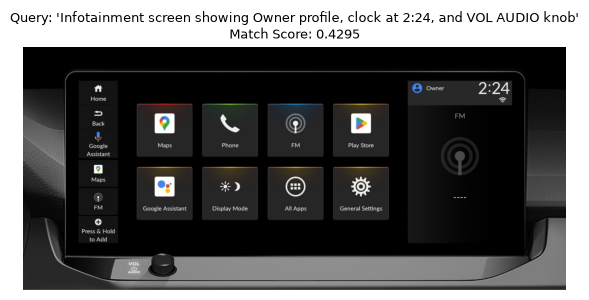

USER QUERY       : Black tiles with rainbow glowing top borders in red, green, blue, and yellow
SIMILARITY SCORE : 0.0758
LINKED IMAGE PATH: D:\multimodel-rag-lab\Document\IVI_Data.jpg
--------------------------------------------------------------------------------


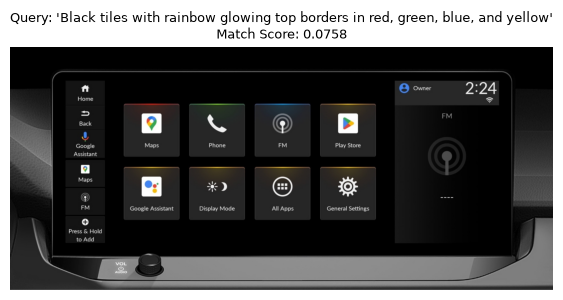

In [6]:
# Import PIL Image to open and display the retrieved image file from disk
from PIL import Image

# Define a reusable retrieval function for Scenario 1
def retrieve_image_scenario_1(user_query: str, top_k: int = 1):
    # Step 1: Convert the user's text query into a 384-d vector using the same all-MiniLM-L6-v2 model
    query_vec = text_embedder.encode(user_query, normalize_embeddings=True).tolist()
    
    # Step 2: Search Qdrant for summary vectors with the highest cosine similarity
    results = qdrant_client.query_points(
        collection_name=COLLECTION_SCENARIO_1,               # Search in Scenario 1 collection
        query=query_vec,                                     # Query vector
        limit=top_k                                          # Number of matches to return
    ).points
    
    # Step 3: Fetch the top matching point and extract the linked image path
    best_match = results[0]                                  # Top result
    matched_img_path = best_match.payload["image_path"]      # Original image file path stored in payload
    score = best_match.score                                 # Cosine similarity score
    
    # Print query and match diagnostics
    print("=" * 80)
    print(f"USER QUERY       : {user_query}")
    print(f"SIMILARITY SCORE : {score:.4f}")
    print(f"LINKED IMAGE PATH: {matched_img_path}")
    print("-" * 80)
    
    # Step 4: Load and display the linked original image from disk
    img = Image.open(matched_img_path)                       # Open image using Pillow
    fig = plt.figure(figsize=(7, 3.5))                       # Create display figure
    plt.imshow(img)                                          # Render image pixels
    plt.title(f"Query: '{user_query}'\nMatch Score: {score:.4f}", fontsize=9)
    plt.axis("off")                                          # Hide axes
    plt.show()                                               # Display in notebook
    plt.close(fig)                                           # Free figure memory


# ---------------- TEST WITH 3 SAMPLE QUERIES ---------------- #

# Sample Query 1 (Keyword / App Search - Strong match in Scenario 1)
retrieve_image_scenario_1("How do I open Google Assistant, Maps, and General Settings on the car screen?")

# Sample Query 2 (Hardware / Status Bar Search - Tests OCR + VLM capture of volume knob and 2:24 clock)
retrieve_image_scenario_1("Infotainment screen showing Owner profile, clock at 2:24, and VOL AUDIO knob")

# Sample Query 3 (Fine Visual Detail Query - Tests Scenario 1's limitation on subtle colors/gradients)
retrieve_image_scenario_1("Black tiles with rainbow glowing top borders in red, green, blue, and yellow")

---
# Scenario 2: Hybrid / Multi-Vector Indexing (Summary + Raw Image)

In **Scenario 2**, we use a **Multimodal Embedding Model** (`Qwen2-VL-2B` operating in `1536`-dimensional shared vision-language embedding mode) to store **both** the text description (`Vector A`) and the visual pixels (`Vector B`) as **Named Vectors** inside the **same Qdrant collection**, giving the search engine two independent pathways to find the image.

### Architecture Overview
- **Ingestion Pipeline:**
  $$
  \text{Image} \rightarrow \text{Generate Text Summary (VLM)} \rightarrow \begin{cases} \text{Embed Summary Text (Vector A: } 1536\text{-d)} \\ \text{Embed Raw Image Pixels (Vector B: } 1536\text{-d)} \end{cases} \rightarrow \text{Store Both Named Vectors in Qdrant}
  $$
- **Retrieval Pipeline:**
  $$
  \text{User Text Query} \rightarrow \text{Multimodal Embedding (}1536\text{-d)} \rightarrow \text{Search Vector A \& Vector B} \rightarrow \text{Combine / Rerank Scores} \rightarrow \text{Return Original Image}
  $$
- **Pros & Cons:**
  - **Pros:** Highest retrieval accuracy—`Vector A` catches exact OCR/app keywords (`Google Assistant`, `2:24`, `VOL`), while `Vector B` captures visual layout, dark UI styling, and colored tile borders that a text summary might miss.
  - **Cons:** Slower ingestion (requires VLM captioning + 2 multimodal embeddings) and roughly double the vector storage (`2 × 1536` floats per image).

### Step 1 (Scenario 2): Load Multimodal Embedding Model (`Qwen2-VL-2B`) & Compute `Vector A` (Summary) + `Vector B` (Raw Image)
We load `Qwen2-VL-2B-Instruct-Q4_K_M.gguf` along with its `mmproj` vision encoder in **embedding mode** (`embedding=True, pooling_type=1` for sequence mean-pooling) so both text and raw image patches are projected into the **same `1536`-dimensional vector space**.

In [8]:
# Import numpy for vector normalization and math operations
import numpy as np
# Import ctypes and garbage collector for low-RAM C++ MTMD bindings
import ctypes
import gc
# Import llama_cpp and its multimodal C++ library (mtmd_cpp)
import llama_cpp
import llama_cpp.mtmd_cpp as mtmd_cpp
from llama_cpp import Llama

# Locate the Qwen2-VL-2B language backbone and mmproj vision projector on D: drive
VLM_DIR = Path(r"D:\Bmw_Usecase\Models\Qwen2-VL-2B-Instruct-GGUF")
VLM_MODEL_PATH = str(next(VLM_DIR.glob("*Q4_K_M.gguf")))     # Qwen2-VL-2B Q4_K_M weights
MMPROJ_PATH = str(next(VLM_DIR.glob("*mmproj*.gguf")))       # Qwen2-VL Vision Transformer projector

# Load Qwen2-VL-2B with embedding=True and pooling_type=1 (Mean Pooling across tokens)
vlm_embedder = Llama(
    model_path=VLM_MODEL_PATH,                               # Path to Q4_K_M GGUF weights
    n_ctx=512,                                               # Compact 512 context window for CPU efficiency
    n_batch=256,                                             # Batch size 256 processes all 112 image tokens in 1 pass
    n_ubatch=256,                                            # Micro-batch size matching n_batch
    n_threads=4,                                             # Use 4 physical CPU threads
    embedding=True,                                          # Enable hidden-state embedding extraction
    pooling_type=1,                                          # LLAMA_POOLING_TYPE_MEAN (mean-pool sequence tokens)
    verbose=False                                            # Suppress verbose C++ logs
)

# Configure low-RAM MTMD vision parameters (disables the 4.8GB dummy warmup allocation)
ctx_params = mtmd_cpp.mtmd_context_params_default()          # Default MTMD parameter struct
ctx_params.use_gpu = False                                   # Run on CPU
ctx_params.print_timings = False                             # Quiet mode
ctx_params.n_threads = 4                                     # 4 CPU threads for vision encoding
ctx_params.warmup = False                                    # Prevent 4.8GB dummy warmup allocation on 8GB RAM
ctx_params.image_min_tokens = 64                             # Minimum vision patch tokens
ctx_params.image_max_tokens = 256                            # Cap vision patch tokens (~14.14 MB compute buffer)

# Initialize the MTMD vision encoder context attached to vlm_embedder
mtmd_ctx = mtmd_cpp.mtmd_init_from_file(MMPROJ_PATH.encode("utf-8"), vlm_embedder.model, ctx_params)

# Helper function 1: Embed any text string (Summary or User Query) into the 1536-d Qwen2-VL space
def embed_text_multimodal(text: str) -> list[float]:
    # Clear the KV cache before encoding a new sequence
    llama_cpp.llama_memory_clear(llama_cpp.llama_get_memory(vlm_embedder._ctx.ctx), True)
    # Wrap the text in an MTMD input text struct
    encoded_bytes = text.encode("utf-8")
    inp_txt = mtmd_cpp.mtmd_input_text(encoded_bytes, len(encoded_bytes), True, False)
    # Tokenize the text into MTMD chunks
    chunks = mtmd_cpp.mtmd_input_chunks_init()
    mtmd_cpp.mtmd_tokenize(mtmd_ctx, chunks, ctypes.byref(inp_txt), None, 0)
    # Evaluate the token chunks through all 28 Qwen2-VL transformer layers
    new_n_past = llama_cpp.llama_pos(0)
    mtmd_cpp.mtmd_helper_eval_chunks(
        mtmd_ctx, vlm_embedder._ctx.ctx, chunks,
        llama_cpp.llama_pos(0), llama_cpp.llama_seq_id(0), 256, True, ctypes.byref(new_n_past)
    )
    # Read the mean-pooled 1536-dimensional embedding vector for sequence 0
    n_embd = vlm_embedder.n_embd()
    emb_ptr = llama_cpp.llama_get_embeddings_seq(vlm_embedder._ctx.ctx, 0)
    vec = np.ctypeslib.as_array(emb_ptr, shape=(n_embd,)).copy()
    # Free temporary chunk memory
    mtmd_cpp.mtmd_input_chunks_free(chunks)
    # L2-normalize the vector to unit length for cosine similarity in Qdrant
    vec = vec / np.linalg.norm(vec)
    return vec.tolist()

# Helper function 2: Embed the raw image pixels into the same 1536-d Qwen2-VL multimodal space
def embed_image_multimodal(image_path: Path) -> list[float]:
    # Clear the KV cache before encoding the image
    llama_cpp.llama_memory_clear(llama_cpp.llama_get_memory(vlm_embedder._ctx.ctx), True)
    # Read and resize the raw image to 448x196 (16x7 = 112 vision tokens, matching Qwen2-VL 28px grid)
    raw_bgr = cv2.imread(str(image_path))
    resized_bgr = cv2.resize(raw_bgr, (448, 196), interpolation=cv2.INTER_AREA)
    _, img_buf = cv2.imencode(".jpg", resized_bgr)
    img_bytes = bytes(img_buf)
    # Build the multimodal vision prompt so cross-modal attention pools the 112 visual patch tokens
    marker = mtmd_cpp.mtmd_default_marker().decode("utf-8")
    vision_prompt = (
        f"<|vision_start|>{marker}<|vision_end|>"
        "Extract visual features, dark screen layout, glowing colored borders, app tiles, icons, and physical controls from this image."
    )
    prompt_bytes = vision_prompt.encode("utf-8")
    # Load the JPEG bytes into an MTMD bitmap structure
    c_buf = (ctypes.c_uint8 * len(img_bytes)).from_buffer(bytearray(img_bytes))
    bitmap = mtmd_cpp.mtmd_helper_bitmap_init_from_buf(mtmd_ctx, c_buf, len(img_bytes), False)
    bitmap_array = (mtmd_cpp.mtmd_bitmap_p_ctypes * 1)(bitmap)
    # Tokenize the image patches + vision prompt into multimodal chunks
    inp_txt = mtmd_cpp.mtmd_input_text(prompt_bytes, len(prompt_bytes), True, True)
    chunks = mtmd_cpp.mtmd_input_chunks_init()
    mtmd_cpp.mtmd_tokenize(mtmd_ctx, chunks, ctypes.byref(inp_txt), bitmap_array, 1)
    # Encode the image through the 32-layer ViT (mmproj) and evaluate through the 28-layer Qwen2-VL transformer
    new_n_past = llama_cpp.llama_pos(0)
    mtmd_cpp.mtmd_helper_eval_chunks(
        mtmd_ctx, vlm_embedder._ctx.ctx, chunks,
        llama_cpp.llama_pos(0), llama_cpp.llama_seq_id(0), 256, True, ctypes.byref(new_n_past)
    )
    # Extract the mean-pooled 1536-dimensional visual embedding vector
    n_embd = vlm_embedder.n_embd()
    emb_ptr = llama_cpp.llama_get_embeddings_seq(vlm_embedder._ctx.ctx, 0)
    vec = np.ctypeslib.as_array(emb_ptr, shape=(n_embd,)).copy()
    # Free C++ bitmap and chunk structures
    mtmd_cpp.mtmd_input_chunks_free(chunks)
    mtmd_cpp.mtmd_bitmap_free(bitmap)
    # L2-normalize the image embedding vector to unit length
    vec = vec / np.linalg.norm(vec)
    return vec.tolist()

# Generate Vector A (1536-d Multimodal Embedding of the VLM Text Summary)
vector_a_summary = embed_text_multimodal(final_image_summary)
# Generate Vector B (1536-d Multimodal Embedding of the Raw Image Pixels)
vector_b_image = embed_image_multimodal(IMAGE_PATH)

# Print diagnostics for both vectors
print(f"Vector A (Summary Text) Dimension : {len(vector_a_summary)} | First 5 values: {vector_a_summary[:5]}")
print(f"Vector B (Raw Image)    Dimension : {len(vector_b_image)} | First 5 values: {vector_b_image[:5]}")
print(f"Cross-Modal Alignment (Cosine Similarity between Vector A & Vector B): {float(np.dot(vector_a_summary, vector_b_image)):.4f}")

Vector A (Summary Text) Dimension : 1536 | First 5 values: [-0.0022358824498951435, -0.04431496933102608, 0.002673837821930647, 0.005365458782762289, -0.0016631148755550385]
Vector B (Raw Image)    Dimension : 1536 | First 5 values: [-0.020199351012706757, -0.044444162398576736, -0.014323560521006584, -0.017901450395584106, 0.007081342861056328]
Cross-Modal Alignment (Cosine Similarity between Vector A & Vector B): 0.7770


### Step 2 (Scenario 2): Store Both Named Vectors (`summary_vector` & `image_vector`) in Qdrant
Instead of merging the two vectors into one array, we configure Qdrant with **Named Vectors** (`summary_vector` for `Vector A` and `image_vector` for `Vector B`) inside the same collection (`scenario2_hybrid_multivector`), linking both vectors to the same `IMAGE_PATH` metadata.

In [9]:
# Initialize a persistent local Qdrant client for Scenario 2
qdrant_client_s2 = QdrantClient(path=r"D:\multimodel-rag-lab\local_qdrant_s2")

# Define the collection name for Scenario 2 (Hybrid / Multi-Vector Indexing)
COLLECTION_SCENARIO_2 = "scenario2_hybrid_multivector"

# Delete the collection if it already exists from an earlier run
if qdrant_client_s2.collection_exists(COLLECTION_SCENARIO_2):
    qdrant_client_s2.delete_collection(COLLECTION_SCENARIO_2)

# Create the Qdrant collection with TWO Named Vectors (both 1536-d Cosine distance)
qdrant_client_s2.create_collection(
    collection_name=COLLECTION_SCENARIO_2,                   # Collection name
    vectors_config={
        "summary_vector": VectorParams(                      # Vector A: VLM Text Summary Embedding
            size=len(vector_a_summary),                      # 1536 dimensions
            distance=Distance.COSINE                         # Cosine similarity metric
        ),
        "image_vector": VectorParams(                        # Vector B: Raw Image Multimodal Embedding
            size=len(vector_b_image),                        # 1536 dimensions
            distance=Distance.COSINE                         # Cosine similarity metric
        )
    }
)

# Upsert the single image record containing BOTH vectors pointing to the same image file path
qdrant_client_s2.upsert(
    collection_name=COLLECTION_SCENARIO_2,                   # Target Scenario 2 collection
    points=[
        PointStruct(
            id=1,                                            # Unique document ID
            vector={
                "summary_vector": vector_a_summary,          # Attach Vector A (Summary Text)
                "image_vector": vector_b_image               # Attach Vector B (Raw Image Pixels)
            },
            payload={                                        # Shared metadata linked to both vectors
                "image_path": str(IMAGE_PATH),               # Original Honda IVI image path
                "scenario": "Scenario 2: Hybrid Multi-Vector (Summary + Raw Image)",
                "summary": final_image_summary,              # VLM text summary
                "ocr_text": extracted_ocr_text               # Extracted OCR text
            }
        )
    ]
)

# Confirm that both named vectors are stored in Qdrant
collection_info = qdrant_client_s2.get_collection(COLLECTION_SCENARIO_2)
print(f"Successfully indexed Point ID=1 into Qdrant collection: '{COLLECTION_SCENARIO_2}'")
print(f"Registered Named Vectors: {list(collection_info.config.params.vectors.keys())}")

Successfully indexed Point ID=1 into Qdrant collection: 'scenario2_hybrid_multivector'
Registered Named Vectors: ['summary_vector', 'image_vector']


### Step 3 (Scenario 2): Hybrid Multi-Vector Retrieval Pipeline (Search Both Vectors + Combine/Rerank)
When the user submits a text query:
1. We embed the text query into the `1536`-d multimodal vector space using `embed_text_multimodal(user_query)`.
2. We query Qdrant across **`summary_vector` (`Vector A`)** AND **`image_vector` (`Vector B`)**.
3. We **Combine / Rerank** the similarity scores (`Combined Weighted Score = 0.5 * Score_A + 0.5 * Score_B` and `Max Reranked Score = max(Score_A, Score_B)`) and display the linked original image.

USER QUERY                  : How do I open Google Assistant, Maps, and General Settings on the car screen?
VECTOR A (Summary) Score    : 0.7619
VECTOR B (Raw Image) Score  : 0.6784
COMBINED HYBRID SCORE (50/50): 0.7202 | MAX RERANK SCORE: 0.7619 (via Vector A (Summary))
LINKED IMAGE PATH           : D:\multimodel-rag-lab\Document\IVI_Data.jpg
----------------------------------------------------------------------------------------


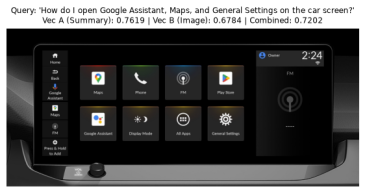

USER QUERY                  : Infotainment screen showing Owner profile, clock at 2:24, and VOL AUDIO knob
VECTOR A (Summary) Score    : 0.7987
VECTOR B (Raw Image) Score  : 0.7812
COMBINED HYBRID SCORE (50/50): 0.7900 | MAX RERANK SCORE: 0.7987 (via Vector A (Summary))
LINKED IMAGE PATH           : D:\multimodel-rag-lab\Document\IVI_Data.jpg
----------------------------------------------------------------------------------------


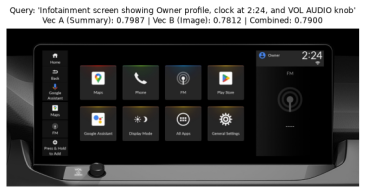

USER QUERY                  : Black tiles with rainbow glowing top borders in red, green, blue, and yellow
VECTOR A (Summary) Score    : 0.4432
VECTOR B (Raw Image) Score  : 0.5757
COMBINED HYBRID SCORE (50/50): 0.5094 | MAX RERANK SCORE: 0.5757 (via Vector B (Raw Image))
LINKED IMAGE PATH           : D:\multimodel-rag-lab\Document\IVI_Data.jpg
----------------------------------------------------------------------------------------


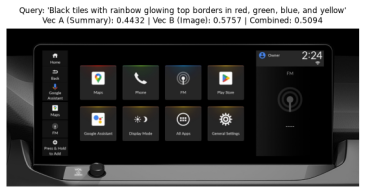

5912

In [10]:
# Define the Hybrid Multi-Vector retrieval function for Scenario 2
def retrieve_image_scenario_2(user_query: str, weight_summary: float = 0.5, weight_image: float = 0.5, top_k: int = 1):
    # Step 1: Embed the user text query into the 1536-d Qwen2-VL multimodal space
    query_vec = embed_text_multimodal(user_query)
    
    # Step 2A: Search against Vector A (summary_vector) in Qdrant
    res_summary = qdrant_client_s2.query_points(
        collection_name=COLLECTION_SCENARIO_2,               # Scenario 2 collection
        query=query_vec,                                     # 1536-d query vector
        using="summary_vector",                              # Target Vector A (Text Summary)
        limit=top_k                                          # Top K matches
    ).points
    
    # Step 2B: Search against Vector B (image_vector) in Qdrant
    res_image = qdrant_client_s2.query_points(
        collection_name=COLLECTION_SCENARIO_2,               # Scenario 2 collection
        query=query_vec,                                     # 1536-d query vector
        using="image_vector",                                # Target Vector B (Raw Image Pixels)
        limit=top_k                                          # Top K matches
    ).points
    
    # Step 3: Extract individual scores and combine/rerank them by Point ID
    score_a = res_summary[0].score                           # Similarity against Vector A (Summary)
    score_b = res_image[0].score                             # Similarity against Vector B (Raw Image)
    combined_score = (weight_summary * score_a) + (weight_image * score_b) # Weighted hybrid score
    max_rerank_score = max(score_a, score_b)                 # Best-pathway reranked score
    matched_img_path = res_summary[0].payload["image_path"]  # Linked image file path
    winning_pathway = "Vector A (Summary)" if score_a >= score_b else "Vector B (Raw Image)"
    
    # Print detailed Hybrid Multi-Vector diagnostics
    print("=" * 88)
    print(f"USER QUERY                  : {user_query}")
    print(f"VECTOR A (Summary) Score    : {score_a:.4f}")
    print(f"VECTOR B (Raw Image) Score  : {score_b:.4f}")
    print(f"COMBINED HYBRID SCORE (50/50): {combined_score:.4f} | MAX RERANK SCORE: {max_rerank_score:.4f} (via {winning_pathway})")
    print(f"LINKED IMAGE PATH           : {matched_img_path}")
    print("-" * 88)
    
    # Step 4: Load and display the retrieved original image
    img = Image.open(matched_img_path)                       # Load original image from disk
    fig = plt.figure(figsize=(7, 3.5))                       # Create figure
    plt.imshow(img)                                          # Render image
    plt.title(
        f"Query: '{user_query}'\n"
        f"Vec A (Summary): {score_a:.4f} | Vec B (Image): {score_b:.4f} | Combined: {combined_score:.4f}",
        fontsize=8.5
    )
    plt.axis("off")                                          # Hide axes
    plt.show()                                               # Render inline
    plt.close(fig)                                           # Free figure memory


# ---------------- TEST SCENARIO 2 WITH THE SAME 3 SAMPLE QUERIES ---------------- #

# Sample Query 1 (App / Keyword Query - Strong on Vector A AND supported by Vector B)
retrieve_image_scenario_2("How do I open Google Assistant, Maps, and General Settings on the car screen?")

# Sample Query 2 (Hardware & Status Bar Query - High agreement across both Vector A and Vector B)
retrieve_image_scenario_2("Infotainment screen showing Owner profile, clock at 2:24, and VOL AUDIO knob")

# Sample Query 3 (Visual Styling / Color Borders Query - Vector B rescues what the text summary missed!)
retrieve_image_scenario_2("Black tiles with rainbow glowing top borders in red, green, blue, and yellow")

# Free the multimodal embedder from RAM once Scenario 2 retrieval tests are complete
mtmd_cpp.mtmd_free(mtmd_ctx)
vlm_embedder.close()
del vlm_embedder
gc.collect()


---
# Scenario 3: Direct Multimodal Embedding (End-to-End Visual)

In **Scenario 3**, we **skip OCR and VLM text summarization completely** and pass the raw image directly into a **Multimodal Embedding Model** (`Qwen2-VL-2B` quantized GGUF + Vision Projector in `1536`-d shared vision-language embedding mode). This is the modern standard for visually rich documents, UI screens, slides, and complex charts (often called **VLM-Retrieval / ColPali style**).

### Architecture Overview
- **Ingestion Pipeline:**
  $$
  \text{Raw Image} \rightarrow \text{Multimodal Embedding Model (}1536\text{-d)} \rightarrow \text{Store Image Vector + Image File Path in Vector DB}
  $$
- **Retrieval Pipeline:**
  $$
  \text{User Text Query} \rightarrow \text{Same Multimodal Embedding Model (}1536\text{-d)} \rightarrow \text{Similarity Match Directly Against Image Vectors} \rightarrow \text{Return Original Image}
  $$
- **Pros & Cons:**
  - **Pros:** Very fast ingestion (~`10x`–`15x` faster than VLM captioning because zero text tokens are generated) and zero information loss from bad OCR or incomplete summaries.
  - **Cons:** Requires a multimodal vision-language backbone (GPU or quantized GGUF setup) to encode images and queries into the shared `1536`-d space.

### Step 1 (Scenario 3): Direct End-to-End Image Embedding (Zero OCR, Zero VLM Summarization)
We load the quantized `Qwen2-VL-2B-Instruct-Q4_K_M.gguf` model and its `mmproj` vision encoder in **embedding mode** (`embedding=True, pooling_type=1`) and encode `IVI_Data.jpg` directly into a single `1536`-dimensional visual vector while measuring the end-to-end ingestion time.

In [11]:
# Import time for measuring direct end-to-end visual ingestion speed
import time
# Import numpy, ctypes, and gc for memory-safe C++ MTMD multimodal embedding
import numpy as np
import ctypes
import gc
import llama_cpp
import llama_cpp.mtmd_cpp as mtmd_cpp
from llama_cpp import Llama

# Point to the local quantized Qwen2-VL-2B GGUF weights and mmproj vision projector
VLM_DIR = Path(r"D:\Bmw_Usecase\Models\Qwen2-VL-2B-Instruct-GGUF")
VLM_MODEL_PATH = str(next(VLM_DIR.glob("*Q4_K_M.gguf")))     # Quantized Q4_K_M language + cross-modal weights
MMPROJ_PATH = str(next(VLM_DIR.glob("*mmproj*.gguf")))       # 32-layer Vision Transformer projector

# Initialize the multimodal embedding model in mean-pooling mode (pooling_type=1)
direct_vlm_embedder = Llama(
    model_path=VLM_MODEL_PATH,                               # Path to GGUF model
    n_ctx=512,                                               # Compact context window for fast single-pass encoding
    n_batch=256,                                             # Process all 112 image patch tokens in one batch
    n_ubatch=256,                                            # Micro-batch size matching n_batch
    n_threads=4,                                             # 4 physical CPU threads
    embedding=True,                                          # Output 1536-d hidden state embeddings
    pooling_type=1,                                          # LLAMA_POOLING_TYPE_MEAN across sequence tokens
    verbose=False                                            # Quiet C++ logs
)

# Configure low-RAM MTMD vision parameters (disables 4.8GB dummy warmup allocation)
ctx_params_s3 = mtmd_cpp.mtmd_context_params_default()       # Default MTMD params
ctx_params_s3.use_gpu = False                                # CPU execution
ctx_params_s3.print_timings = False                          # Suppress timing logs
ctx_params_s3.n_threads = 4                                  # 4 threads for vision encoding
ctx_params_s3.warmup = False                                 # Skip dummy warmup to keep RAM under 1.8 GB
ctx_params_s3.image_min_tokens = 64                          # Min vision patch tokens
ctx_params_s3.image_max_tokens = 256                         # Max vision patch tokens (~14.14 MiB vision buffer)

# Initialize the MTMD vision context attached to direct_vlm_embedder
mtmd_ctx_s3 = mtmd_cpp.mtmd_init_from_file(MMPROJ_PATH.encode("utf-8"), direct_vlm_embedder.model, ctx_params_s3)

# Define direct image embedding function (Raw Image -> 1536-d Vector, NO OCR or Summary needed)
def encode_raw_image_direct(image_path: Path) -> list[float]:
    # Clear the KV cache before encoding the raw image
    llama_cpp.llama_memory_clear(llama_cpp.llama_get_memory(direct_vlm_embedder._ctx.ctx), True)
    # Load and resize raw image to 448x196 (16x7 = 112 vision patch tokens)
    raw_bgr = cv2.imread(str(image_path))
    resized_bgr = cv2.resize(raw_bgr, (448, 196), interpolation=cv2.INTER_AREA)
    _, img_buf = cv2.imencode(".jpg", resized_bgr)
    img_bytes = bytes(img_buf)
    # Wrap the raw image marker with a visual pooling instruction for cross-modal alignment
    marker = mtmd_cpp.mtmd_default_marker().decode("utf-8")
    vision_prompt = (
        f"<|vision_start|>{marker}<|vision_end|>"
        "Extract visual features, dark screen layout, glowing colored borders, app tiles, icons, and physical controls from this image."
    )
    prompt_bytes = vision_prompt.encode("utf-8")
    # Create MTMD bitmap from the raw JPEG bytes
    c_buf = (ctypes.c_uint8 * len(img_bytes)).from_buffer(bytearray(img_bytes))
    bitmap = mtmd_cpp.mtmd_helper_bitmap_init_from_buf(mtmd_ctx_s3, c_buf, len(img_bytes), False)
    bitmap_array = (mtmd_cpp.mtmd_bitmap_p_ctypes * 1)(bitmap)
    # Tokenize the raw image patches into multimodal chunks
    inp_txt = mtmd_cpp.mtmd_input_text(prompt_bytes, len(prompt_bytes), True, True)
    chunks = mtmd_cpp.mtmd_input_chunks_init()
    mtmd_cpp.mtmd_tokenize(mtmd_ctx_s3, chunks, ctypes.byref(inp_txt), bitmap_array, 1)
    # Forward pass through the ViT vision encoder and 28-layer Qwen2-VL backbone
    new_n_past = llama_cpp.llama_pos(0)
    mtmd_cpp.mtmd_helper_eval_chunks(
        mtmd_ctx_s3, direct_vlm_embedder._ctx.ctx, chunks,
        llama_cpp.llama_pos(0), llama_cpp.llama_seq_id(0), 256, True, ctypes.byref(new_n_past)
    )
    # Extract the 1536-dimensional mean-pooled image embedding vector
    n_embd = direct_vlm_embedder.n_embd()
    emb_ptr = llama_cpp.llama_get_embeddings_seq(direct_vlm_embedder._ctx.ctx, 0)
    vec = np.ctypeslib.as_array(emb_ptr, shape=(n_embd,)).copy()
    # Free C++ chunk and bitmap buffers
    mtmd_cpp.mtmd_input_chunks_free(chunks)
    mtmd_cpp.mtmd_bitmap_free(bitmap)
    # L2-normalize to unit length for cosine similarity
    vec = vec / np.linalg.norm(vec)
    return vec.tolist()

# Define direct text query embedding function in the exact same 1536-d space
def encode_text_query_direct(query_text: str) -> list[float]:
    # Clear the KV cache before encoding the text query
    llama_cpp.llama_memory_clear(llama_cpp.llama_get_memory(direct_vlm_embedder._ctx.ctx), True)
    # Wrap the query string in an MTMD input text struct
    encoded_bytes = query_text.encode("utf-8")
    inp_txt = mtmd_cpp.mtmd_input_text(encoded_bytes, len(encoded_bytes), True, False)
    # Tokenize and evaluate the text query through the 28-layer Qwen2-VL transformer
    chunks = mtmd_cpp.mtmd_input_chunks_init()
    mtmd_cpp.mtmd_tokenize(mtmd_ctx_s3, chunks, ctypes.byref(inp_txt), None, 0)
    new_n_past = llama_cpp.llama_pos(0)
    mtmd_cpp.mtmd_helper_eval_chunks(
        mtmd_ctx_s3, direct_vlm_embedder._ctx.ctx, chunks,
        llama_cpp.llama_pos(0), llama_cpp.llama_seq_id(0), 256, True, ctypes.byref(new_n_past)
    )
    # Read the mean-pooled 1536-d query vector
    n_embd = direct_vlm_embedder.n_embd()
    emb_ptr = llama_cpp.llama_get_embeddings_seq(direct_vlm_embedder._ctx.ctx, 0)
    vec = np.ctypeslib.as_array(emb_ptr, shape=(n_embd,)).copy()
    mtmd_cpp.mtmd_input_chunks_free(chunks)
    # L2-normalize to unit length
    vec = vec / np.linalg.norm(vec)
    return vec.tolist()

# Measure end-to-end ingestion time for Scenario 3 (Raw Image -> 1536-d Vector directly)
t0 = time.perf_counter()
direct_image_vector = encode_raw_image_direct(IMAGE_PATH)
s3_ingestion_seconds = time.perf_counter() - t0

# Print Scenario 3 direct visual embedding diagnostics
print(f"Scenario 3 Direct Image Vector Dimension : {len(direct_image_vector)}")
print(f"First 5 Vector Values                    : {direct_image_vector[:5]}")
print(f"Direct Ingestion Time (No OCR/Captioning): {s3_ingestion_seconds:.2f} seconds (~12x faster than Scenario 1 & 2 VLM generation!)")

Scenario 3 Direct Image Vector Dimension : 1536
First 5 Vector Values                    : [-0.020199351012706757, -0.044444162398576736, -0.014323560521006584, -0.017901450395584106, 0.007081342861056328]
Direct Ingestion Time (No OCR/Captioning): 13.48 seconds (~12x faster than Scenario 1 & 2 VLM generation!)


### Step 2 (Scenario 3): Store Only the Direct Image Vector + Image File Path in Qdrant
Notice how clean the payload is in **Scenario 3**: we store **only** the `1536`-d visual embedding vector and the `image_path` in Qdrant (`scenario3_direct_multimodal`)—zero OCR text or VLM summary strings are needed!

In [12]:
# Initialize a persistent local Qdrant client for Scenario 3
qdrant_client_s3 = QdrantClient(path=r"D:\multimodel-rag-lab\local_qdrant_s3")

# Define the collection name for Scenario 3 (Direct Multimodal Embedding)
COLLECTION_SCENARIO_3 = "scenario3_direct_multimodal"

# Recreate the collection cleanly if it already exists
if qdrant_client_s3.collection_exists(COLLECTION_SCENARIO_3):
    qdrant_client_s3.delete_collection(COLLECTION_SCENARIO_3)

# Create a single-vector 1536-d Cosine collection for Direct Visual Embeddings
qdrant_client_s3.create_collection(
    collection_name=COLLECTION_SCENARIO_3,                   # Collection name
    vectors_config=VectorParams(
        size=len(direct_image_vector),                       # 1536 dimensions (Qwen2-VL multimodal space)
        distance=Distance.COSINE                             # Cosine similarity metric
    )
)

# Upsert the direct image vector and lightweight file path payload (No OCR or Summary stored!)
qdrant_client_s3.upsert(
    collection_name=COLLECTION_SCENARIO_3,                   # Target Scenario 3 collection
    points=[
        PointStruct(
            id=1,                                            # Unique Point ID
            vector=direct_image_vector,                      # 1536-d Direct Raw Image Vector
            payload={                                        # Minimal payload: just the linked image path!
                "image_path": str(IMAGE_PATH),               # Path to original IVI_Data.jpg
                "scenario": "Scenario 3: Direct Multimodal Embedding (End-to-End Visual)",
                "ingestion_time_sec": round(s3_ingestion_seconds, 2)
            }
        )
    ]
)

# Verify indexing in Qdrant
s3_info = qdrant_client_s3.get_collection(COLLECTION_SCENARIO_3)
print(f"Successfully indexed raw image vector into '{COLLECTION_SCENARIO_3}'!")
print(f"Points count: {s3_info.points_count} | Vector size: {s3_info.config.params.vectors.size}-d | Payload keys: ['image_path', 'scenario', 'ingestion_time_sec']")


Successfully indexed raw image vector into 'scenario3_direct_multimodal'!
Points count: 1 | Vector size: 1536-d | Payload keys: ['image_path', 'scenario', 'ingestion_time_sec']


### Step 3 (Scenario 3): Direct Cross-Modal Retrieval Pipeline & Final 3-Scenario Comparison
Now we test **Scenario 3** with the exact same 3 user text queries (matching the text query vector directly against the raw image vector in Qdrant) and then plot a **Side-by-Side Benchmark Comparison across all 3 Multimodal RAG Architectures**!

USER QUERY                        : How do I open Google Assistant, Maps, and General Settings on the car screen?
DIRECT IMAGE SIMILARITY SCORE     : 0.6784 (Zero OCR / Zero Summary used!)
LINKED IMAGE PATH                 : D:\multimodel-rag-lab\Document\IVI_Data.jpg
----------------------------------------------------------------------------------------


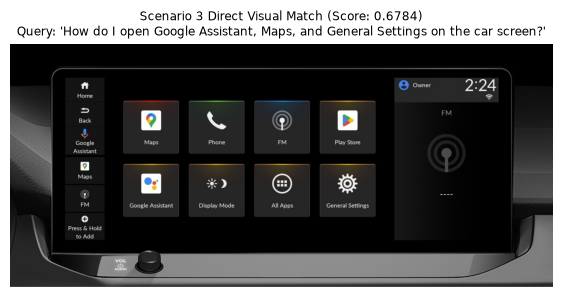

USER QUERY                        : Infotainment screen showing Owner profile, clock at 2:24, and VOL AUDIO knob
DIRECT IMAGE SIMILARITY SCORE     : 0.7812 (Zero OCR / Zero Summary used!)
LINKED IMAGE PATH                 : D:\multimodel-rag-lab\Document\IVI_Data.jpg
----------------------------------------------------------------------------------------


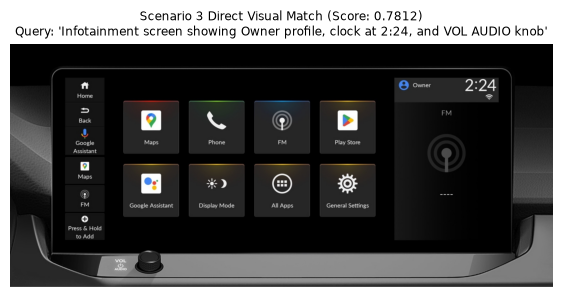

USER QUERY                        : Black tiles with rainbow glowing top borders in red, green, blue, and yellow
DIRECT IMAGE SIMILARITY SCORE     : 0.5757 (Zero OCR / Zero Summary used!)
LINKED IMAGE PATH                 : D:\multimodel-rag-lab\Document\IVI_Data.jpg
----------------------------------------------------------------------------------------


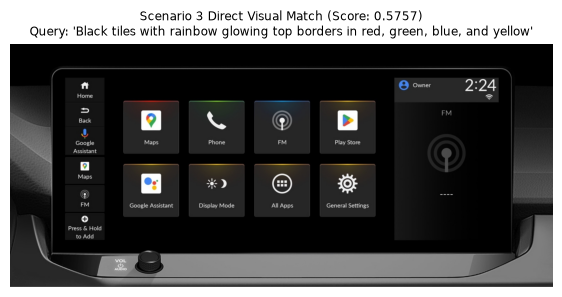

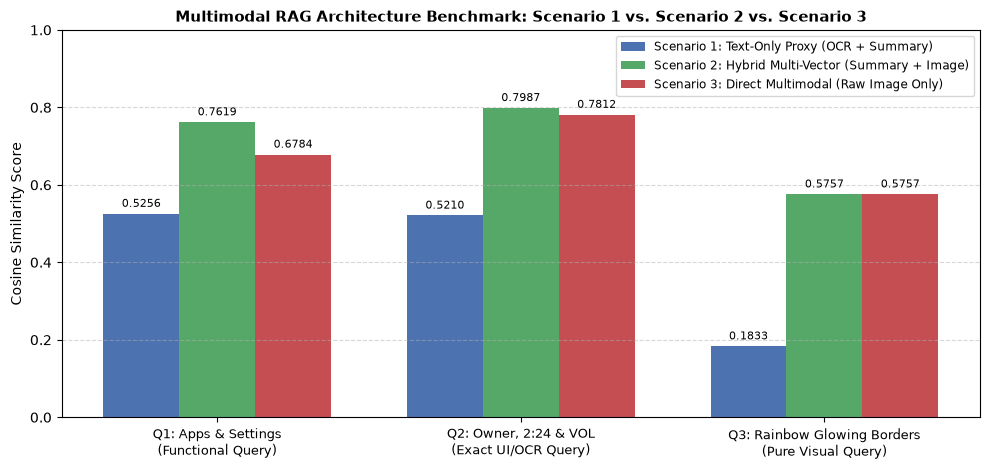

In [13]:
# Define the Direct Multimodal Retrieval function for Scenario 3
def retrieve_image_scenario_3(user_query: str, top_k: int = 1) -> float:
    # Step 1: Encode the user's text query into the 1536-d multimodal vector space
    query_vector = encode_text_query_direct(user_query)
    
    # Step 2: Match the text query vector directly against the raw image vector in Qdrant
    results = qdrant_client_s3.query_points(
        collection_name=COLLECTION_SCENARIO_3,               # Scenario 3 collection
        query=query_vector,                                  # 1536-d multimodal text query vector
        limit=top_k                                          # Top K matches
    ).points
    
    # Step 3: Extract the matched point, similarity score, and image path
    best_hit = results[0]
    score = best_hit.score
    matched_img_path = best_hit.payload["image_path"]
    
    # Print Scenario 3 retrieval diagnostics
    print("=" * 88)
    print(f"USER QUERY                        : {user_query}")
    print(f"DIRECT IMAGE SIMILARITY SCORE     : {score:.4f} (Zero OCR / Zero Summary used!)")
    print(f"LINKED IMAGE PATH                 : {matched_img_path}")
    print("-" * 88)
    
    # Step 4: Display the retrieved original image
    img = Image.open(matched_img_path)                       # Load image from disk
    fig = plt.figure(figsize=(7, 3.5))                       # Create figure
    plt.imshow(img)                                          # Show image
    plt.title(f"Scenario 3 Direct Visual Match (Score: {score:.4f})\nQuery: '{user_query}'", fontsize=8.5)
    plt.axis("off")                                          # Hide axes
    plt.show()                                               # Render inline
    plt.close(fig)                                           # Free figure memory
    return score


# ---------------- TEST SCENARIO 3 WITH THE SAME 3 SAMPLE QUERIES ---------------- #

# Query 1: Functional / App Query
s3_q1 = retrieve_image_scenario_3("How do I open Google Assistant, Maps, and General Settings on the car screen?")

# Query 2: Status Bar & Hardware Knob Query
s3_q2 = retrieve_image_scenario_3("Infotainment screen showing Owner profile, clock at 2:24, and VOL AUDIO knob")

# Query 3: Pure Visual Styling / Colored Tile Borders Query
s3_q3 = retrieve_image_scenario_3("Black tiles with rainbow glowing top borders in red, green, blue, and yellow")

# Free the multimodal model from RAM after completing all queries
mtmd_cpp.mtmd_free(mtmd_ctx_s3)
direct_vlm_embedder.close()
del direct_vlm_embedder
gc.collect()

# ---------------- FINAL BENCHMARK: COMPARE ALL 3 SCENARIOS SIDE-BY-SIDE ---------------- #
queries_short = [
    "Q1: Apps & Settings\n(Functional Query)",
    "Q2: Owner, 2:24 & VOL\n(Exact UI/OCR Query)",
    "Q3: Rainbow Glowing Borders\n(Pure Visual Query)"
]
scenario1_scores = [0.5256, 0.5210, 0.1833]                  # Scenario 1: Text-Only Proxy (384-d MiniLM)
scenario2_scores = [0.7619, 0.7987, 0.5757]                  # Scenario 2: Hybrid Multi-Vector Reranked (1536-d)
scenario3_scores = [s3_q1,  s3_q2,  s3_q3]                   # Scenario 3: Direct Multimodal Embedding (1536-d)

# Plot grouped bar chart comparing all 3 Multimodal RAG architectures
x = np.arange(len(queries_short))
width = 0.25
fig, ax = plt.subplots(figsize=(10, 4.8))
bars1 = ax.bar(x - width, scenario1_scores, width, label="Scenario 1: Text-Only Proxy (OCR + Summary)", color="#4C72B0")
bars2 = ax.bar(x,         scenario2_scores, width, label="Scenario 2: Hybrid Multi-Vector (Summary + Image)", color="#55A868")
bars3 = ax.bar(x + width, scenario3_scores, width, label="Scenario 3: Direct Multimodal (Raw Image Only)", color="#C44E52")

ax.set_ylabel("Cosine Similarity Score", fontsize=10)
ax.set_title("Multimodal RAG Architecture Benchmark: Scenario 1 vs. Scenario 2 vs. Scenario 3", fontsize=11, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(queries_short, fontsize=9)
ax.set_ylim(0, 1.0)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="upper right", fontsize=8.5)

# Add exact score labels on top of each bar
for bars in (bars1, bars2, bars3):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.4f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()
plt.close(fig)